In [9]:
!git clone https://github.com/cornell-happi-lab/HS2026-1D-curvature.git
!find HS2026-1D-curvature -not -path "*/.git*" | head -60

fatal: destination path 'HS2026-1D-curvature' already exists and is not an empty directory.
HS2026-1D-curvature
HS2026-1D-curvature/.vscode
HS2026-1D-curvature/.vscode/settings.json
HS2026-1D-curvature/readme.md
HS2026-1D-curvature/validation
HS2026-1D-curvature/validation/validation_data.xlsx
HS2026-1D-curvature/validation/mygui_sensor_natural.py
HS2026-1D-curvature/validation/daily_objects
HS2026-1D-curvature/validation/daily_objects/tuna_can
HS2026-1D-curvature/validation/daily_objects/tuna_can/hold_20251009_135059_ref6.00_curv15.csv
HS2026-1D-curvature/validation/daily_objects/tuna_can/hold_20251009_135049_ref4.00_curv15.csv
HS2026-1D-curvature/validation/daily_objects/tuna_can/hold_20251009_143153_refNA_curv15.csv
HS2026-1D-curvature/validation/daily_objects/tuna_can/hold_20251009_135120_ref8.00_curv15.csv
HS2026-1D-curvature/validation/daily_objects/tuna_can/hold_20251009_135038_ref2.00_curv15.csv
HS2026-1D-curvature/validation/daily_objects/energy_drink
HS2026-1D-curvature/valid

In [2]:
import pandas as pd, glob, os

repo = "HS2026-1D-curvature"

# 1. Full README
print(open(f"{repo}/readme.md").read())
print("=" * 70)

# 2. One raw recording
f = sorted(glob.glob(f"{repo}/validation/daily_objects/tuna_can/*ref4.00*.csv"))[0]
df = pd.read_csv(f)
print("Example file:", os.path.basename(f))
print("Shape:", df.shape)
print("Columns:", list(df.columns))
print(df.head(10))
print(df.describe().T)
print("=" * 70)

# 3. The processing script (how the lab summarizes recordings)
print(open(f"{repo}/validation/cal_avg_stddev.py").read()[:4000])
print("=" * 70)

# 4. The Excel file: sheets and first rows
xl = pd.ExcelFile(f"{repo}/validation/validation_data.xlsx")
for sheet in xl.sheet_names:
    d = xl.parse(sheet)
    print(f"--- Sheet '{sheet}': shape {d.shape}")
    print(d.head(8))

## 0. Directory Diagram
```
3D_print
    ├── fixture_resin
    ├── MLPdataset
    ├── sensor_case
arduino_code
    ├── multi_test
    ├── single_node
calibration_code
    ├── calibration_data
    ├── calibration_static_multinodes.py
    ├── model_predictNN.py
    ├── plot_static.py
MLPtraining
    ├── runs_strong
    ├── baseline.py
    ├── realtime_prediction_strong_save.py
    ├── sensor_data.csv
    ├── train_strong.py
PCB
    ├── gerbers
    ├── main_board
validation
    ├── daily_objects
    ├── cal_avg_stddev.py
    ├── mygui_sensor_natural.py
    ├── mygui_sensor.py
    ├── validation_data.xlsx
orders.xlsx
```
## 1. Hardware
The tactile sensor is fabricated following a resistive-based design commonly used in tactile sensing research. All required materials — including sensor fabrication supplies, PCB components, cables, and connectors — are listed in [`orders`](orders.xlsx). 

We used KiCad for both the schematic design and PCB layout. The complete board files are available at [

In [4]:
import numpy as np, pandas as pd
from sklearn.linear_model import RidgeCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedKFold, LeaveOneGroupOut, cross_val_predict
from sklearn.metrics import mean_absolute_error

repo = "HS2026-1D-curvature"
cd = pd.read_csv(f"{repo}/MLPtraining/sensor_data.csv", sep=r"\s+")
NODES = [f"node{i}" for i in range(1, 17)]
X, y = cd[NODES].to_numpy(), cd["kappa"].to_numpy()
print("Shape:", cd.shape)
print("Samples per curvature:\n", cd["kappa"].value_counts().sort_index())

# Correlation of each node with curvature (4x4 grid layout)
corr = np.array([np.corrcoef(cd[n], y)[0, 1] for n in NODES]).reshape(4, 4)
print("\nCorrelation of each node with curvature (4x4 grid):\n", corr.round(2))

# First comparison: ridge regression under two evaluation schemes
model = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-3, 3, 13)))

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
pred_random = cross_val_predict(model, X, y, cv=skf.split(X, y))
pred_loco = cross_val_predict(model, X, y, cv=LeaveOneGroupOut(), groups=y)

print(f"\nRidge, random split (lab-style):      MAE = {mean_absolute_error(y, pred_random):.2f} m^-1")
print(f"Ridge, leave-one-curvature-out:       MAE = {mean_absolute_error(y, pred_loco):.2f} m^-1")
print("\nPer held-out curvature (leave-one-curvature-out):")
for k in np.unique(y):
    m = y == k
    print(f"  kappa = {k:5.1f}: mean prediction {pred_loco[m].mean():6.1f}, MAE {np.abs(pred_loco[m] - k).mean():5.2f}")

Shape: (270, 17)
Samples per curvature:
 kappa
0     30
10    30
20    30
30    30
40    30
50    30
60    30
70    30
80    30
Name: count, dtype: int64

Correlation of each node with curvature (4x4 grid):
 [[0.54 0.53 0.6  0.23]
 [0.59 0.59 0.63 0.28]
 [0.58 0.6  0.63 0.31]
 [0.58 0.51 0.51 0.16]]

Ridge, random split (lab-style):      MAE = 11.73 m^-1
Ridge, leave-one-curvature-out:       MAE = 14.73 m^-1

Per held-out curvature (leave-one-curvature-out):
  kappa =   0.0: mean prediction   23.2, MAE 23.20
  kappa =  10.0: mean prediction   26.1, MAE 16.12
  kappa =  20.0: mean prediction   19.8, MAE  6.26
  kappa =  30.0: mean prediction   28.9, MAE  8.15
  kappa =  40.0: mean prediction   39.0, MAE  6.32
  kappa =  50.0: mean prediction   49.4, MAE 13.48
  kappa =  60.0: mean prediction   54.7, MAE 12.58
  kappa =  70.0: mean prediction   53.3, MAE 17.48
  kappa =  80.0: mean prediction   75.7, MAE 28.98


In [6]:
import torch, torch.nn as nn
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.base import BaseEstimator, RegressorMixin
import warnings; warnings.filterwarnings("ignore")

def summary_feats(Xn):
    """Rotation/flip-invariant summaries of the 16 nodes (same idea as the lab's features)."""
    return np.column_stack([Xn.sum(1), Xn.mean(1), Xn.std(1), Xn.min(1), Xn.max(1),
                            Xn.max(1) - Xn.min(1), np.linalg.norm(Xn, axis=1),
                            np.quantile(Xn, .75, 1) - np.quantile(Xn, .25, 1)])

# ---- Lab's residual MLP, re-implemented from train_strong.py ----
class ResBlock(nn.Module):
    def __init__(self, d, p):
        super().__init__()
        self.seq = nn.Sequential(nn.Linear(d, d), nn.SiLU(), nn.Dropout(p), nn.Linear(d, d))
        self.act = nn.SiLU()
    def forward(self, x): return self.act(x + self.seq(x))

class StrongMLP(nn.Module):
    def __init__(self, in_dim=24, p=0.10, w=128):
        super().__init__()
        self.stem = nn.Sequential(nn.Linear(in_dim, w), nn.LayerNorm(w), nn.SiLU(), nn.Dropout(p))
        self.blocks = nn.Sequential(ResBlock(w, p), ResBlock(w, p), ResBlock(w, p))
        self.head = nn.Sequential(nn.Linear(w, 64), nn.SiLU(), nn.Dropout(p), nn.Linear(64, 1))
    def forward(self, x): return self.head(self.blocks(self.stem(x)))

class LabMLP(BaseEstimator, RegressorMixin):
    def __init__(self, epochs=500, lr=2e-3, wd=1e-4, bs=64, mixup=0.15, seed=0):
        self.epochs, self.lr, self.wd, self.bs, self.mixup, self.seed = epochs, lr, wd, bs, mixup, seed
    def _prep(self, Xn, fit=False):
        if fit: self.nm, self.ns = Xn.mean(0), Xn.std(0) + 1e-8
        z = (Xn - self.nm) / self.ns
        f = summary_feats(z)
        if fit: self.fm, self.fs = f.mean(0), f.std(0) + 1e-8
        return np.hstack([z, (f - self.fm) / self.fs]).astype(np.float32)
    def fit(self, Xn, y):
        torch.manual_seed(self.seed); np.random.seed(self.seed)
        Xt = torch.tensor(self._prep(Xn, fit=True)); yt = torch.tensor(y / 100.0, dtype=torch.float32)[:, None]
        self.net = StrongMLP(in_dim=Xt.shape[1]); opt = torch.optim.AdamW(self.net.parameters(), lr=self.lr, weight_decay=self.wd)
        self.net.train()
        for _ in range(self.epochs):
            perm = torch.randperm(len(Xt))
            for i in range(0, len(Xt), self.bs):
                b = perm[i:i + self.bs]; xb, yb = Xt[b], yt[b]
                lam = np.random.beta(self.mixup, self.mixup); j = torch.randperm(len(b))
                xb, yb = lam * xb + (1 - lam) * xb[j], lam * yb + (1 - lam) * yb[j]
                loss = nn.functional.mse_loss(self.net(xb), yb)
                opt.zero_grad(); loss.backward(); opt.step()
        return self
    def predict(self, Xn):
        self.net.eval()
        with torch.no_grad():
            return self.net(torch.tensor(self._prep(Xn))).numpy().ravel() * 100.0

# ---- Models to compare ----
from sklearn.preprocessing import FunctionTransformer
SF = FunctionTransformer(summary_feats)
models = {
    "Ridge (16 raw nodes)":       make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-3, 3, 13))),
    "Ridge (8 summary features)": make_pipeline(SF, StandardScaler(), RidgeCV(alphas=np.logspace(-3, 3, 13))),
    "kNN (summary features)":     make_pipeline(SF, StandardScaler(), KNeighborsRegressor(n_neighbors=7)),
    "Random forest (raw nodes)":  RandomForestRegressor(n_estimators=300, random_state=0),
    "Random forest (summary)":    make_pipeline(SF, RandomForestRegressor(n_estimators=300, random_state=0)),
    "Lab's residual MLP":         LabMLP(),
}

results = []
interior = (y > 0) & (y < 80)
for name, m in models.items():
    p_rand = cross_val_predict(m, X, y, cv=list(skf.split(X, y)))
    p_loco = cross_val_predict(m, X, y, cv=list(LeaveOneGroupOut().split(X, y, groups=y)))
    results.append(dict(model=name,
                        random_MAE=mean_absolute_error(y, p_rand),
                        unseen_MAE=mean_absolute_error(y, p_loco),
                        unseen_interior_MAE=mean_absolute_error(y[interior], p_loco[interior])))
    print(f"{name} done")

print(pd.DataFrame(results).round(2).to_string(index=False))

Ridge (16 raw nodes) done
Ridge (8 summary features) done
kNN (summary features) done
Random forest (raw nodes) done
Random forest (summary) done
Lab's residual MLP done
                     model  random_MAE  unseen_MAE  unseen_interior_MAE
      Ridge (16 raw nodes)       11.73       14.73                11.48
Ridge (8 summary features)       15.17       18.77                14.50
    kNN (summary features)       11.19       17.06                13.67
 Random forest (raw nodes)        8.82       15.41                11.30
   Random forest (summary)       10.56       17.33                13.69
        Lab's residual MLP        5.86       13.70                10.32


In [7]:
from sklearn.base import clone

def cv_mae(model, Xs, y, scheme, n_per=None, seed=0):
    """MAE with optional subsampling of training placements per curvature."""
    rs = np.random.default_rng(seed)
    if scheme == "random":
        splits = list(skf.split(Xs, y)); eval_mask = np.ones(len(y), bool)
    else:  # unseen curvatures, interior only (10-70)
        splits = [(tr, te) for tr, te in LeaveOneGroupOut().split(Xs, y, groups=y) if 0 < y[te][0] < 80]
        eval_mask = (y > 0) & (y < 80)
    pred = np.full(len(y), np.nan)
    for tr, te in splits:
        if n_per is not None:
            tr = np.concatenate([rs.choice(tr[y[tr] == k], min(n_per, (y[tr] == k).sum()), replace=False)
                                 for k in np.unique(y[tr])])
        pred[te] = clone(model).fit(Xs[tr], y[tr]).predict(Xs[te])
    return mean_absolute_error(y[eval_mask], pred[eval_mask])

base = {"Ridge": models["Ridge (16 raw nodes)"],
        "Random forest": models["Random forest (raw nodes)"],
        "Lab's MLP": LabMLP()}

# (a) Does the weak 4th column matter? Compare all 16 nodes vs. dropping nodes 4, 8, 12, 16
keep12 = [i for i in range(16) if (i + 1) % 4 != 0]
print("(a) Dropping the weak 4th column of nodes")
for name, m in base.items():
    for label, cols in [("16 nodes", list(range(16))), ("12 nodes", keep12)]:
        r = cv_mae(m, X[:, cols], y, "random"); u = cv_mae(m, X[:, cols], y, "unseen")
        print(f"  {name:14s} {label}: random MAE {r:5.2f} | unseen-interior MAE {u:5.2f}")

# (b) Data efficiency: placements per curvature in training
print("\n(b) Placements per curvature")
rows = []
for n in [5, 10, 20, None]:
    for name, m in base.items():
        rows.append(dict(placements=("all" if n is None else n), model=name,
                         random_MAE=cv_mae(m, X, y, "random", n),
                         unseen_interior_MAE=cv_mae(m, X, y, "unseen", n)))
    print(f"  placements={n} done")
print(pd.DataFrame(rows).round(2).to_string(index=False))

(a) Dropping the weak 4th column of nodes
  Ridge          16 nodes: random MAE 11.73 | unseen-interior MAE 11.48
  Ridge          12 nodes: random MAE 12.53 | unseen-interior MAE 11.82
  Random forest  16 nodes: random MAE  8.82 | unseen-interior MAE 11.30
  Random forest  12 nodes: random MAE  8.86 | unseen-interior MAE 11.21
  Lab's MLP      16 nodes: random MAE  5.86 | unseen-interior MAE 10.32
  Lab's MLP      12 nodes: random MAE  6.35 | unseen-interior MAE 10.71

(b) Placements per curvature
  placements=5 done
  placements=10 done
  placements=20 done
  placements=None done
placements         model  random_MAE  unseen_interior_MAE
         5         Ridge       12.37                11.79
         5 Random forest       12.61                14.54
         5     Lab's MLP       11.72                11.61
        10         Ridge       11.91                12.76
        10 Random forest       10.79                12.30
        10     Lab's MLP        8.92                12.16
     

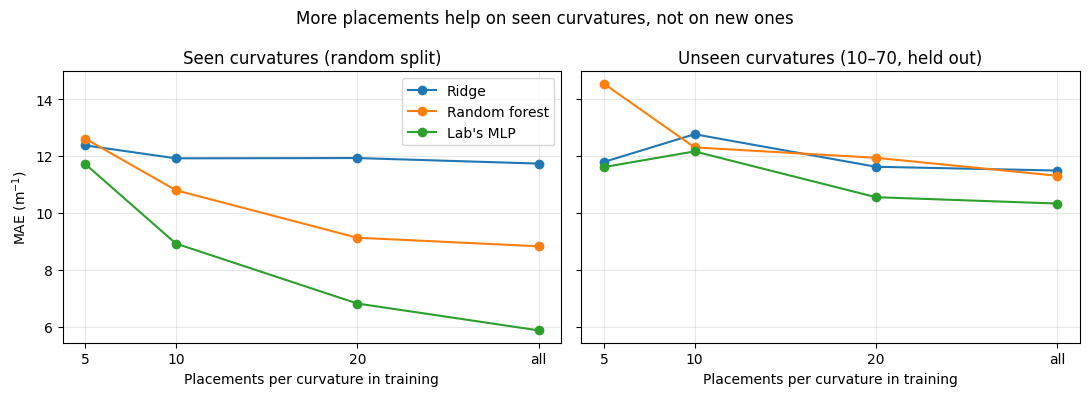

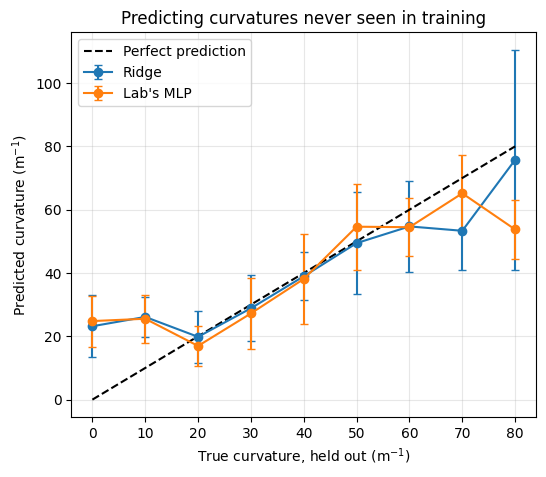

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [8]:
import matplotlib.pyplot as plt

# Figure 1: data efficiency
lc = pd.DataFrame(rows)
lc["n"] = lc.placements.replace("all", 30).astype(int)
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, col, title in [(axes[0], "random_MAE", "Seen curvatures (random split)"),
                       (axes[1], "unseen_interior_MAE", "Unseen curvatures (10–70, held out)")]:
    for name in ["Ridge", "Random forest", "Lab's MLP"]:
        d = lc[lc.model == name]
        ax.plot(d.n, d[col], marker="o", label=name)
    ax.set_title(title); ax.set_xlabel("Placements per curvature in training"); ax.grid(alpha=0.3)
    ax.set_xticks([5, 10, 20, 30]); ax.set_xticklabels(["5", "10", "20", "all"])
axes[0].set_ylabel("MAE (m$^{-1}$)"); axes[0].legend()
plt.suptitle("More placements help on seen curvatures, not on new ones")
plt.tight_layout(); plt.savefig("data_efficiency.png", dpi=200, bbox_inches="tight"); plt.show()

# Figure 2: predictions for each held-out curvature (lab's MLP vs. ridge)
fig, ax = plt.subplots(figsize=(6, 5))
for name, m in [("Ridge", base["Ridge"]), ("Lab's MLP", LabMLP())]:
    p = cross_val_predict(m, X, y, cv=list(LeaveOneGroupOut().split(X, y, groups=y)))
    means = [p[y == k].mean() for k in np.unique(y)]
    sds = [p[y == k].std() for k in np.unique(y)]
    ax.errorbar(np.unique(y), means, yerr=sds, marker="o", capsize=3, label=name)
ax.plot([0, 80], [0, 80], "k--", label="Perfect prediction")
ax.set_xlabel("True curvature, held out (m$^{-1}$)"); ax.set_ylabel("Predicted curvature (m$^{-1}$)")
ax.set_title("Predicting curvatures never seen in training"); ax.legend(); ax.grid(alpha=0.3)
plt.savefig("unseen_predictions.png", dpi=200, bbox_inches="tight"); plt.show()

from google.colab import files
files.download("data_efficiency.png"); files.download("unseen_predictions.png")